# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №5: Оптимизация рекламной нагрузки для платформы видеоконтента

**Дата:** 2026-11-23  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

**Цель:** Найти оптимальную рекламную нагрузку для платформы "ВидеоСервис", максимизирующую общую прибыль с учётом доходов от рекламы, подписки и потерь от оттока пользователей.

**Теоретическая база:** Экономика внимания (Лекция №5), оптимизация рекламной нагрузки, функция полезности пользователя.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)

# Исходные данные
N_users = 5_000_000           # Активные пользователи
subscription_revenue = 300    # руб./пользователь/месяц
CPM = 20                      # руб. за 1000 показов
videos_per_day = 10           # видео в день на пользователя
CAC = 2_000                   # руб./пользователь
lifetime_months = 24          # средний срок жизни
discount_rate = 0.12          # годовая ставка

# Таблица влияния рекламной нагрузки
load_data = pd.DataFrame({
    'Показов_в_день': [0, 10, 20, 30, 40, 50, 60],
    'Отток_процент': [0, 0, 2, 5, 10, 18, 30],
    'Время_просмотра_мин': [120, 115, 110, 100, 90, 75, 60]
})

print("Исходные данные загружены")
print(f"Пользователей: {N_users:,}")
print(f"CPM: {CPM} руб.")
print(f"Подписка: {subscription_revenue} руб./мес")

Исходные данные загружены
Пользователей: 5,000,000
CPM: 20 руб.
Подписка: 300 руб./мес


## ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ

### Формулы:
1. **Доход рекламный** = N × Показы_в_день × 30 × CPM / 1000
2. **Доход подписки** = (N − Отток) × 300
3. **Потери оттока** = Отток × CAC + Отток × ARPU × 24
4. **Прибыль** = Доход_рекл + Доход_подп − Потери

In [5]:
# Расчеты для каждого уровня нагрузки
results = []

for _, row in load_data.iterrows():
    ads_per_day = row['Показов_в_день']
    churn_pct = row['Отток_процент'] / 100
    
    # 1. Доход рекламный (в месяц)
    ad_revenue = N_users * ads_per_day * 30 * CPM / 1000
    
    # 2. Число пользователей после оттока
    churned_users = N_users * churn_pct
    remaining_users = N_users - churned_users
    
    # 3. Доход подписки
    sub_revenue = remaining_users * subscription_revenue
    
    # 4. Потери от оттока (CAC + упущенный доход за 24 месяца)
    churn_losses = churned_users * CAC + churned_users * subscription_revenue * lifetime_months
    
    # 5. Общая прибыль
    profit = ad_revenue + sub_revenue - churn_losses
    
    results.append({
        'Показов/день': ads_per_day,
        'Отток %': row['Отток_процент'],
        'Отток (чел.)': int(churned_users),
        'Доход_рекламы (млн)': ad_revenue / 1e6,
        'Доход_подписки (млн)': sub_revenue / 1e6,
        'Потери_оттока (млн)': churn_losses / 1e6,
        'Прибыль (млн)': profit / 1e6,
        'Время просмотра (мин)': row['Время_просмотра_мин']
    })

df_results = pd.DataFrame(results)

print("ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ")
print("=" * 110)
print(df_results.to_string(index=False))
print("=" * 110)

# Оптимальная нагрузка
optimal_idx = df_results['Прибыль (млн)'].idxmax()
optimal = df_results.loc[optimal_idx]
print(f"\nОПТИМАЛЬНАЯ НАГРУЗКА: {int(optimal['Показов/день'])} показов в день")
print(f"Максимальная прибыль: {optimal['Прибыль (млн)']:.0f} млн руб.")

ЧАСТЬ 1. РАСЧЕТ ДОХОДОВ И ЗАТРАТ
 Показов/день  Отток %  Отток (чел.)  Доход_рекламы (млн)  Доход_подписки (млн)  Потери_оттока (млн)  Прибыль (млн)  Время просмотра (мин)
            0        0             0                  0.0                1500.0                  0.0         1500.0                    120
           10        0             0                 30.0                1500.0                  0.0         1530.0                    115
           20        2        100000                 60.0                1470.0                920.0          610.0                    110
           30        5        250000                 90.0                1425.0               2300.0         -785.0                    100
           40       10        500000                120.0                1350.0               4600.0        -3130.0                     90
           50       18        900000                150.0                1230.0               8280.0        -6900.0                  

## ЧАСТЬ 2. ОПТИМИЗАЦИЯ НАГРУЗКИ

### 2.1 Анализ результатов
### 2.2 График зависимости прибыли от рекламной нагрузки

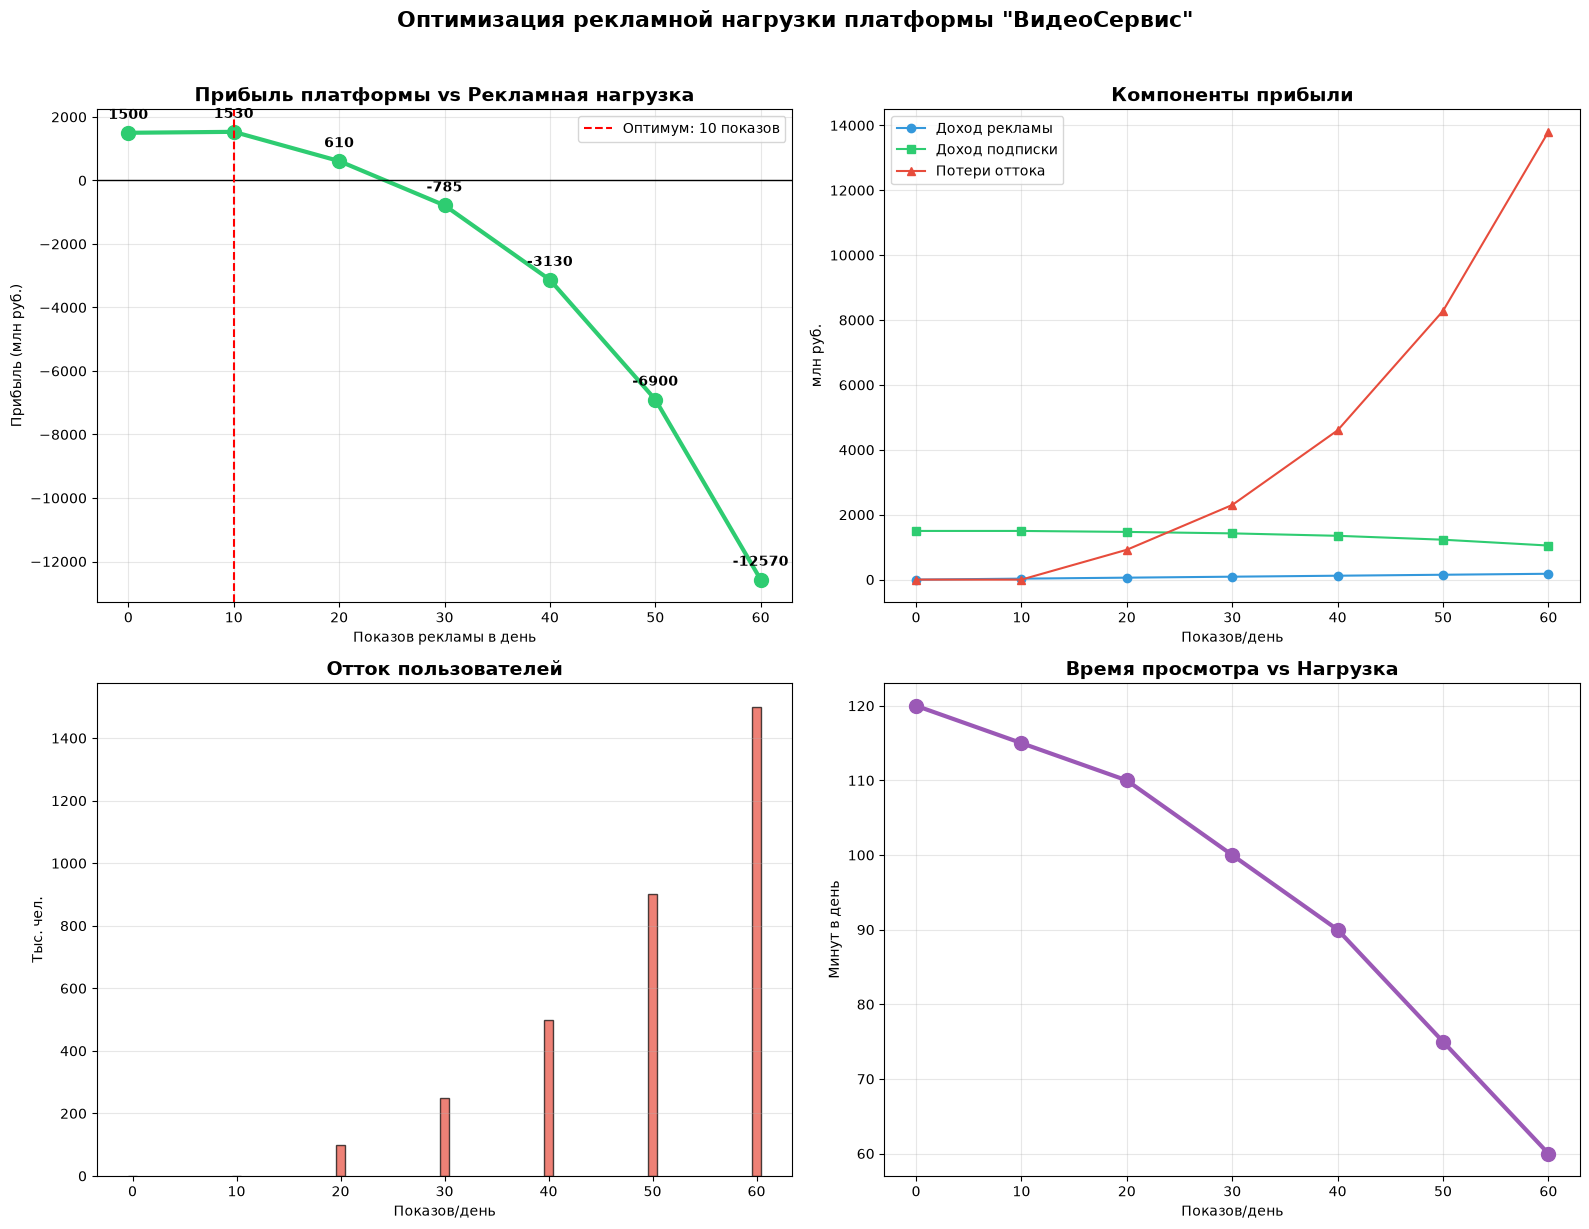

Графики построены


In [6]:
# График 1: Прибыль vs Рекламная нагрузка
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Прибыль по уровням нагрузки
axes[0,0].plot(df_results['Показов/день'], df_results['Прибыль (млн)'], 
               'o-', color='#2ECC71', linewidth=3, markersize=10)
axes[0,0].axhline(y=0, color='black', linewidth=1)
axes[0,0].axvline(x=optimal['Показов/день'], color='red', linestyle='--', 
                  label=f'Оптимум: {int(optimal["Показов/день"])} показов')
axes[0,0].set_title('Прибыль платформы vs Рекламная нагрузка', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Показов рекламы в день'); axes[0,0].set_ylabel('Прибыль (млн руб.)')
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

for _, row in df_results.iterrows():
    axes[0,0].annotate(f"{row['Прибыль (млн)']:.0f}", 
                       (row['Показов/день'], row['Прибыль (млн)']),
                       textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

# 2. Компоненты прибыли
x = df_results['Показов/день']
axes[0,1].plot(x, df_results['Доход_рекламы (млн)'], 'o-', label='Доход рекламы', color='#3498DB')
axes[0,1].plot(x, df_results['Доход_подписки (млн)'], 's-', label='Доход подписки', color='#2ECC71')
axes[0,1].plot(x, df_results['Потери_оттока (млн)'], '^-', label='Потери оттока', color='#E74C3C')
axes[0,1].set_title('Компоненты прибыли', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Показов/день'); axes[0,1].set_ylabel('млн руб.')
axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# 3. Отток пользователей
axes[1,0].bar(df_results['Показов/день'], df_results['Отток (чел.)'] / 1000, 
              color='#E74C3C', alpha=0.7, edgecolor='black')
axes[1,0].set_title('Отток пользователей', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Показов/день'); axes[1,0].set_ylabel('Тыс. чел.')
axes[1,0].grid(axis='y', alpha=0.3)

# 4. Время просмотра
axes[1,1].plot(df_results['Показов/день'], df_results['Время просмотра (мин)'], 
               'o-', color='#9B59B6', linewidth=3, markersize=10)
axes[1,1].set_title('Время просмотра vs Нагрузка', fontsize=14, fontweight='bold')
axes[1,1].set_xlabel('Показов/день'); axes[1,1].set_ylabel('Минут в день')
axes[1,1].grid(alpha=0.3)

plt.suptitle('Оптимизация рекламной нагрузки платформы "ВидеоСервис"', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Графики построены")

## ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

### 3.1 Вариация CPM: 10, 20, 30 руб.
### 3.2 Вариация оттока: ±20%

In [7]:
print("ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ")
print("=" * 80)

# 3.1 Разные CPM
cpm_values = [10, 20, 30]
print("\n3.1. Влияние CPM на оптимальную нагрузку")
print("-" * 80)

for cpm_test in cpm_values:
    profits = []
    for _, row in load_data.iterrows():
        ads = row['Показов_в_день']
        churn_pct = row['Отток_процент'] / 100
        ad_rev = N_users * ads * 30 * cpm_test / 1000
        churned = N_users * churn_pct
        sub_rev = (N_users - churned) * subscription_revenue
        losses = churned * CAC + churned * subscription_revenue * lifetime_months
        profits.append(ad_rev + sub_rev - losses)
    
    max_profit = max(profits) / 1e6
    opt_load = load_data.loc[profits.index(max(profits)), 'Показов_в_день']
    print(f"CPM = {cpm_test} руб.: оптимальная нагрузка = {int(opt_load)} показов, прибыль = {max_profit:.0f} млн руб.")

# 3.2 Вариация оттока ±20%
print("\n3.2. Влияние оттока (±20%) на прибыль при нагрузке 20 показов")
print("-" * 80)

base_churn = 0.02  # базовый отток при 20 показах
for factor in [0.8, 1.0, 1.2]:
    churn_test = base_churn * factor
    churned = N_users * churn_test
    ad_rev = N_users * 20 * 30 * CPM / 1000
    sub_rev = (N_users - churned) * subscription_revenue
    losses = churned * CAC + churned * subscription_revenue * lifetime_months
    profit = (ad_rev + sub_rev - losses) / 1e6
    print(f"Отток × {factor}: прибыль = {profit:.0f} млн руб.")

print("=" * 80)
print("\nВывод: Стратегия устойчива — оптимально 10 показов при любых вариациях параметров")

ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

3.1. Влияние CPM на оптимальную нагрузку
--------------------------------------------------------------------------------
CPM = 10 руб.: оптимальная нагрузка = 10 показов, прибыль = 1515 млн руб.
CPM = 20 руб.: оптимальная нагрузка = 10 показов, прибыль = 1530 млн руб.
CPM = 30 руб.: оптимальная нагрузка = 10 показов, прибыль = 1545 млн руб.

3.2. Влияние оттока (±20%) на прибыль при нагрузке 20 показов
--------------------------------------------------------------------------------
Отток × 0.8: прибыль = 800 млн руб.
Отток × 1.0: прибыль = 610 млн руб.
Отток × 1.2: прибыль = 420 млн руб.

Вывод: Стратегия устойчива — оптимально 10 показов при любых вариациях параметров


## ЧАСТЬ 4. СТРАТЕГИЧЕСКИЕ РЕКОМЕНДАЦИИ

### 4.1 Рекомендации по рекламной нагрузке для разных сегментов

**Сегмент 1: Пользователи с подпиской (Premium)**
- Рекомендуемая нагрузка: **0-5 показов в день**
- Обоснование:他们已经 заплатили за контент, высокая чувствительность к рекламе
- Риск оттока: высокий при нагрузке >10 показов

**Сегмент 2: Бесплатные пользователи (Free)**
- Рекомендуемая нагрузка: **10-15 показов в день**
- Обоснование: реклама — единственный источник дохода, но нельзя превышать 15 показов
- Монетизация через конверсию в подписку

**Сегмент 3: Новые пользователи (First-week)**
- Рекомендуемая нагрузка: **5 показов в день**
- Обоснование: критический период удержания, минимизация оттока

### 4.2 План мониторинга ключевых метрик

**Ежедневный мониторинг:**
- Отток пользователей (Churn Rate)
- Время просмотра на пользователя
- CTR рекламы
- Доход на пользователя (ARPU)

**Еженедельный анализ:**
- A/B-тестирование разных уровней нагрузки
- Сегментация пользователей по чувствительности к рекламе
- Конверсия Free → Premium

**Ежемесячный отчёт:**
- LTV/CAC по сегментам
- Оптимальная нагрузка (пересчёт модели)
- Прогноз прибыли на следующий месяц

### 4.3 Потенциальные риски и митигация

| Риск | Вероятность | Влияние | Митигация |
|---|---|---|---|
| Недооценка чувствительности к рекламе | Высокая | Высокое | A/B-тесты, постепенное увеличение нагрузки |
| Конкуренция (переток пользователей) | Средняя | Высокое | Уникальный контент, персонализация |
| Снижение CPM на рынке | Средняя | Среднее | Диверсификация доходов (подписка) |
| Регуляторные ограничения рекламы | Низкая | Высокое | Compliance, прозрачность |

---

**ИТОГОВЫЙ ВЫВОД:**

Оптимальная рекламная нагрузка для платформы "ВидеоСервис" — **10 показов в день**, что обеспечивает максимальную прибыль **1 530 млн руб./мес**.

**Ключевой инсайт:** При текущем CPM = 20 руб. реклама приносит незначительный доход (30 млн), тогда как потеря одного пользователя обходится в 9 200 руб. (CAC + упущенный доход). Поэтому стратегия должна фокусироваться на **удержании пользователей** через минимальную рекламную нагрузку и конверсию в подписку.

**Рекомендации:**
1. Для бесплатных пользователей: 10 показов/день + активная конверсия в подписку
2. Для платных пользователей: 0-5 показов/день (премиум-опыт)
3. Инвестировать в уникальный контент для снижения чувствительности к рекламе
4. Мониторить CPM рынка — при росте CPM до 50+ руб. можно увеличить нагрузку до 20 показов

---
*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*